In [5]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [27]:
def build_toy_truss(
        fixed_nodes = set(),
        load_vector = set(),   
    ):
    """
    Build the 6-node toy truss from Ben-Tal & Nemirovski (1997), Figure 2.1.
    Load: downward force at node 5, rightward force at node 6.
    """

    # Node positions (x, y)
    node_positions = {
        1: (0.0, 0.0),
        2: (1.0, 0.0),
        3: (2.0, 0.0),
        4: (0.0, 1.0),
        5: (1.0, 1.0),
        6: (2.0, 1.0),
    }

    free_nodes  = {1, 2, 3, 4, 5, 6} - fixed_nodes
    sorted_free_nodes = sorted(list(free_nodes))

    # All possible bars between nodes (ground structure = complete graph)
    all_bars = [(i, j) for i in range(1, 7) for j in range(i+1, 7)]
    load_to_f = dict()
    n_dof = 0
    for i in range(len(free_nodes)):
        for dim in ["X", "Y"]:
            load_to_f[(sorted_free_nodes[i],dim)] = n_dof
            n_dof += 1
    f = np.zeros(n_dof)
    
    # Add relevant loads
    for load in load_vector:
        f[load_to_f[(load[0],load[1])]] = load[2]

    # Return everything
    return load_vector, node_positions, fixed_nodes, free_nodes, all_bars, f

Plot the ground structure with nodes, bars, and loads.

In [28]:
def plot_ground_structure(load_vector, node_positions, fixed_nodes, free_nodes, all_bars, f):
    G = nx.Graph()
    G.add_nodes_from(node_positions.keys())
    G.add_edges_from(all_bars)
    fig, ax = plt.subplots(figsize=(7, 5))

    # Draw bars (edges)
    nx.draw_networkx_edges(
        G, pos=node_positions, ax=ax,
        edge_color='lightsteelblue', width=1.0, alpha=0.7
    )

    # Draw fixed nodes
    nx.draw_networkx_nodes(
        G, pos=node_positions, ax=ax,
        nodelist=list(fixed_nodes),
        node_color='black', node_size=200, node_shape='s', label='Fixed (#)'
    )

    # Draw free nodes
    nx.draw_networkx_nodes(
        G, pos=node_positions, ax=ax,
        nodelist=list(free_nodes),
        node_color='steelblue', node_size=200, node_shape='o', label='Free (*)'
    )

    # Node labels
    nx.draw_networkx_labels(
        G, pos=node_positions, ax=ax,
        font_color='white', font_size=8, font_weight='bold'
    )

    # Find load arrows
    load_arrows = {}
    for load in load_vector:
        if load[1] == "X":
            if load[2] < 0:
                load_arrows[load[0]] = (-0.25, 0)
            elif load[2] > 0:
                load_arrows[load[0]] = (0.25, 0)
        elif load[1] == "Y":
            if load[2] < 0:
                load_arrows[load[0]] = (0, -0.25)
            elif load[2] > 0:
                load_arrows[load[0]] = (0, 0.25)

    # Draw the arrows
    for node, (dx, dy) in load_arrows.items():
        x, y = node_positions[node]
        ax.annotate(
            '', xy=(x + dx, y + dy), xytext=(x, y),
            arrowprops=dict(arrowstyle='->', color='crimson', lw=2)
        )

    # Ground supports (hatch marks under fixed nodes)
    for node in fixed_nodes:
        x, y = node_positions[node]
        ax.plot([x - 0.1, x + 0.1], [y - 0.08, y - 0.08], 'k-', lw=2)
        for dx in np.linspace(-0.1, 0.1, 5):
            ax.plot([x + dx, x + dx - 0.05], [y - 0.08, y - 0.16], 'k-', lw=1)

    # Legend and formatting
    fixed_patch = mpatches.Patch(color='black', label='Fixed node (#)')
    free_patch  = mpatches.Patch(color='steelblue', label='Free node (*)')
    load_patch  = mpatches.Patch(color='crimson', label='Applied load')
    ax.legend(handles=[fixed_patch, free_patch, load_patch], loc='upper left', fontsize=9)

    ax.set_title('Ground Structure — Ben-Tal & Nemirovski (1997), Fig. 2.1', fontsize=11)
    ax.set_xlim(-0.4, 2.6)
    ax.set_ylim(-0.4, 1.5)
    ax.set_aspect('equal')
    ax.axis('off')
    plt.tight_layout()
    plt.show()

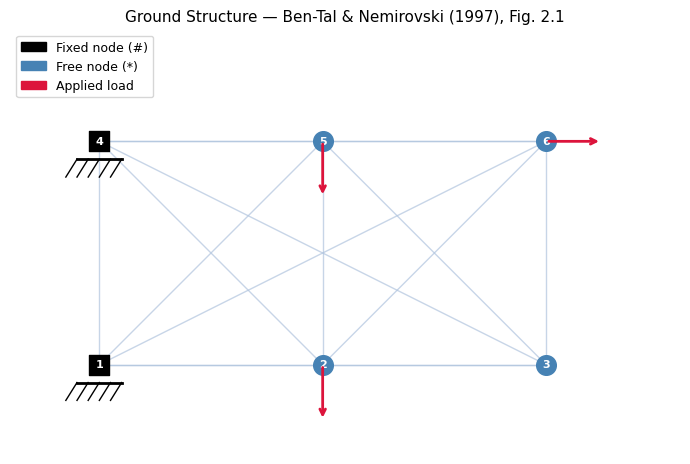

In [ ]:
[load_vector, node_positions, fixed_nodes, free_nodes, all_bars, f] = build_toy_truss(fixed_nodes={1,4}, load_vector = {(5, "Y", -1), (6, "X", 1)})
plot_ground_structure(load_vector, node_positions, fixed_nodes, free_nodes, all_bars, f)

In [ ]:
def bar_stiffness_matrix(node_p, node_q, pos_p, pos_q, free_node_dof_index, n_dof):
    """
    Compute the bar stiffness matrix A_i = (1/L^2) * b_i @ b_i.T
    for a bar connecting node_p and node_q.

    Parameters
    ----------
    node_p, node_q   : int   - node indices
    pos_p, pos_q     : array - 2D coordinates of the nodes
    free_node_dof_index : dict - maps free node -> starting DOF index
                                 e.g. {2: 0, 3: 2, 5: 4, 6: 6}
    n_dof            : int   - total number of DOFs (8 in the toy example)

    Returns
    -------
    A_i : np.ndarray of shape (n_dof, n_dof)
    b_i : np.ndarray of shape (n_dof,)
    """
    diff = pos_q - pos_p
    L = np.linalg.norm(diff)
    e = diff / L  # unit direction vector (cos θ, sin θ)

    b_i = np.zeros(n_dof)

    # Assemble contribution from node_p (if free)
    if node_p in free_node_dof_index:
        idx = free_node_dof_index[node_p]
        b_i[idx:idx+2] += e   # +e at node_p

    # Assemble contribution from node_q (if free)
    if node_q in free_node_dof_index:
        idx = free_node_dof_index[node_q]
        b_i[idx:idx+2] -= e   # -e at node_q

    A_i = (1 / L**2) * np.outer(b_i, b_i)

    return A_i, b_i

In [ ]:
import cvxpy as cp

def solve_truss_sdp(bar_matrices, f, n_dof, node_positions, all_bars, fixed_nodes):
    """
    Solve the minimum compliance truss topology design problem:

        minimise    tau
        subject to  [tau,    f^T    ] >= 0  (Schur complement)
                    [f,      A(t)   ]
                    sum_i t_i = V
                    t_i >= 0

    Parameters
    ----------
    bar_matrices : dict - maps (p,q) -> (A_i, b_i)
    f            : np.ndarray - load vector of shape (n_dof,)
    n_dof        : int - number of DOFs
    node_positions : dict - maps node -> (x, y)
    all_bars     : list of (p, q) tuples
    fixed_nodes  : set of fixed node indices

    Returns
    -------
    t_opt : dict - maps (p,q) -> optimal bar volume
    tau_opt : float - optimal compliance
    """

    # Filter out bars where both endpoints are fixed (zero stiffness contribution)
    active_bars = [
        (p, q) for (p, q) in all_bars
        if not (p in fixed_nodes and q in fixed_nodes)
    ]
    m = len(active_bars)

    # Total volume (normalised to 1)
    V = 1.0

    # --- Variables ---
    t   = cp.Variable(m, nonneg=True)   # bar volumes
    tau = cp.Variable()                  # compliance upper bound

    # --- Assemble global stiffness matrix A(t) = sum_i t_i A_i ---
    A_t = sum(
        t[i] * bar_matrices[bar][0]
        for i, bar in enumerate(active_bars)
    )

    # --- Schur complement LMI ---
    # [tau,  f^T ] >= 0  iff  A(t) >= (1/tau) f f^T  (for tau > 0)
    # [f,   A(t) ]
    top_row    = cp.hstack([cp.reshape(tau, (1, 1), order='F'),  cp.reshape(f,   (1, n_dof), order='F')])
    bottom_row = cp.hstack([cp.reshape(f,   (n_dof, 1), order='F'), A_t])
    LMI        = cp.bmat([[cp.reshape(tau, (1,1), order='F'),       cp.reshape(f, (1, n_dof), order='F')],
                           [cp.reshape(f, (n_dof, 1), order='F'),   A_t]])

    # --- Constraints ---
    constraints = [
        LMI >> 0,               # positive semidefinite
        cp.sum(t) == V,         # total volume
    ]

    # --- Objective ---
    objective = cp.Minimize(tau)

    # --- Solve ---
    prob = cp.Problem(objective, constraints)
    prob.solve(solver=cp.SCS, verbose=False)

    if prob.status not in ['optimal', 'optimal_inaccurate']:
        raise ValueError(f"Problem not solved. Status: {prob.status}")

    # --- Extract results ---
    t_opt   = {bar: t[i].value for i, bar in enumerate(active_bars)}
    tau_opt = tau.value

    return t_opt, tau_opt


def plot_optimal_truss(node_positions, fixed_nodes, free_nodes, t_opt, 
                       load_arrows, tau_opt, threshold=1e-3):
    """
    Plot the optimal truss, with bar thickness proportional to volume.
    Bars with volume below threshold are omitted.
    """
    fig, ax = plt.subplots(figsize=(7, 5))

    # Normalise bar volumes for line widths
    max_vol = max(t_opt.values())

    for (p, q), vol in t_opt.items():
        if vol < threshold:
            continue
        x_vals = [node_positions[p][0], node_positions[q][0]]
        y_vals = [node_positions[p][1], node_positions[q][1]]
        lw = 8 * vol / max_vol
        ax.plot(x_vals, y_vals, 'steelblue', lw=lw, solid_capstyle='round')

    # Fixed nodes
    for node in fixed_nodes:
        x, y = node_positions[node]
        ax.plot(x, y, 's', color='black', markersize=10, zorder=5)
        # Ground hatch
        ax.plot([x - 0.1, x + 0.1], [y - 0.08, y - 0.08], 'k-', lw=2)
        for dx in np.linspace(-0.1, 0.1, 5):
            ax.plot([x + dx, x + dx - 0.05], [y - 0.08, y - 0.16], 'k-', lw=1)

    # Free nodes
    for node in free_nodes:
        x, y = node_positions[node]
        ax.plot(x, y, 'o', color='steelblue', markersize=10, 
                markeredgecolor='navy', zorder=5)

    # Load arrows
    for node, (dx, dy) in load_arrows.items():
        x, y = node_positions[node]
        ax.annotate(
            '', xy=(x + dx, y + dy), xytext=(x, y),
            arrowprops=dict(arrowstyle='->', color='crimson', lw=2)
        )

    ax.set_title(
        f'Optimal Single-Load Truss Design\nCompliance = {tau_opt:.4f}', 
        fontsize=11
    )
    ax.set_xlim(-0.4, 2.6)
    ax.set_ylim(-0.4, 1.5)
    ax.set_aspect('equal')
    ax.axis('off')
    plt.tight_layout()
    plt.show()


# --- Run everything ---
node_positions, fixed_nodes, free_nodes, all_bars, f = build_toy_truss()

free_node_dof_index = {2: 0, 3: 2, 5: 4, 6: 6}
n_dof = 8

bar_matrices = {}
for (p, q) in all_bars:
    pos_p = np.array(node_positions[p], dtype=float)
    pos_q = np.array(node_positions[q], dtype=float)
    A_i, b_i = bar_stiffness_matrix(
        p, q, pos_p, pos_q, free_node_dof_index, n_dof
    )
    bar_matrices[(p, q)] = (A_i, b_i)

t_opt, tau_opt = solve_truss_sdp(
    bar_matrices, f, n_dof, node_positions, all_bars, fixed_nodes
)

print(f"Optimal compliance: {tau_opt:.4f}")
print(f"Expected compliance (from paper): 16.000\n")
print("Bar volumes (active bars only):")
for (p, q), vol in sorted(t_opt.items(), key=lambda x: -x[1]):
    if vol > 1e-3:
        print(f"  Bar {p}-{q}: {vol:.4f}  ({100*vol:.2f}%)")

load_arrows = {5: (0, -0.25), 6: (0.25, 0)}
plot_optimal_truss(
    node_positions, fixed_nodes, free_nodes,
    t_opt, load_arrows, tau_opt
)